<a href="https://colab.research.google.com/github/ArifahZhafirah/PEMBELAJARAN-MESIN/blob/main/JS08/TUGAS-LAB02/PEMMESTUGAS2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Lab 2 - HDBSCAN pada Dataset Iris

Persiapan Lingkungan

In [7]:
# Instalasi library hdbscan (tidak tersedia default di sklearn)
!pip install hdbscan

# Import modul
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
import hdbscan

Fungsi Visualisasi

In [8]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

Load Dataset Iris

In [9]:
df = pd.read_csv('Iris.csv')
df.info()

# Fitur: 4 kolom ukuran bunga (kolom Id dan Species tidak dipakai sebagai fitur)
X = df.iloc[:, 1:5].values
# Label asli (Species) diubah ke angka untuk perbandingan
labels_true, kelas = pd.factorize(df['Species'])
print(X.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
(150, 4)


Membuat Model HDBSCAN dan melaporkan jumlah cluster dan noise

In [10]:
hdb = hdbscan.HDBSCAN().fit(X)

n_clusters = len(set(hdb.labels_)) - (1 if -1 in hdb.labels_ else 0)
n_noise = list(hdb.labels_).count(-1)
print("Jumlah cluster:", n_clusters)
print("Jumlah noise  :", n_noise)

Jumlah cluster: 2
Jumlah noise  : 0


Reduksi dimensi dengan PCA dan visualisasi hasil clustering vs label asli

Variansi yang dijelaskan: 0.9776317750248062


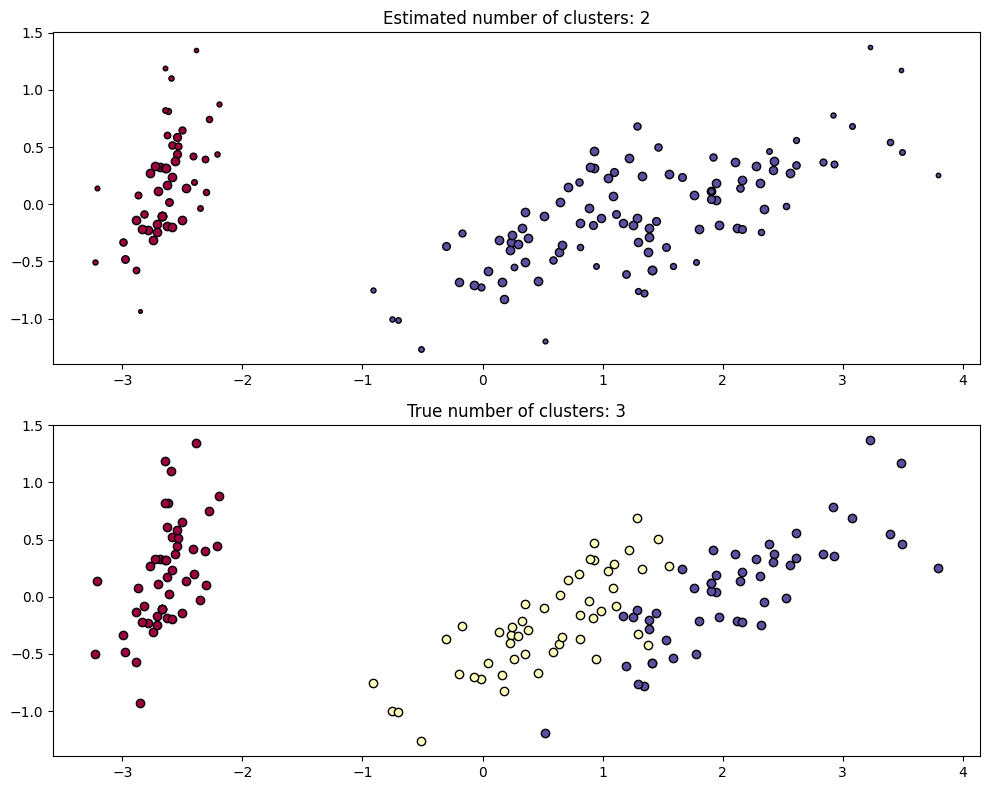

In [11]:
# Data 4 dimensi, direduksi ke 2 dimensi agar bisa divisualisasikan
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print("Variansi yang dijelaskan:", pca.explained_variance_ratio_.sum())

fig, axes = plt.subplots(2, 1, figsize=(10, 8))
plot(X_pca, hdb.labels_, hdb.probabilities_, ax=axes[0])
plot(X_pca, labels_true, ground_truth=True, ax=axes[1])
plt.show()

Dua komponen PCA menjelaskan sekitar 97,76% variansi data, jadi plot 2D ini sudah mewakili data dengan baik.

Perbandingan dengan label asli dan evaluasi

In [12]:
print(pd.crosstab(df['Species'], pd.Series(hdb.labels_, name='Cluster HDBSCAN')))

sil_score = silhouette_score(X, hdb.labels_)
dbi_score = davies_bouldin_score(X, hdb.labels_)
print(f"Silhouette Score: {sil_score}")
print(f"Davies-Bouldin Index: {dbi_score}")

Cluster HDBSCAN   0   1
Species                
Iris-setosa      50   0
Iris-versicolor   0  50
Iris-virginica    0  50
Silhouette Score: 0.6863930543445408
Davies-Bouldin Index: 0.3835952094491397


#Analisis

HDBSCAN pada dataset Iris menghasilkan 2 cluster dan 0 titik noise, sedangkan label asli memiliki
3 spesies. Hasil clustering ini tidak sepenuhnya sesuai dengan label asli. Spesies Iris-setosa
(50 data) terpisah sempurna menjadi satu cluster karena ukuran kelopaknya jauh berbeda dari dua
spesies lain. Sebaliknya, Iris-versicolor dan Iris-virginica (100 data) digabung menjadi satu
cluster karena kedua spesies tersebut saling berdekatan dan tumpang tindih pada ruang fitur,
sehingga tidak ada celah kepadatan yang cukup jelas bagi HDBSCAN untuk memisahkannya. Silhouette
Score sebesar 0,6864 dan Davies-Bouldin Index sebesar 0,3836 menunjukkan bahwa dua kelompok yang
terbentuk memang terpisah dengan baik, tetapi nilai ini mencerminkan pemisahan setosa terhadap
sisanya, bukan pemisahan tiga spesies yang sebenarnya. Perubahan min_cluster_size dari 3 sampai 15
juga tetap menghasilkan 2 cluster. Dengan demikian HDBSCAN berhasil menemukan struktur alami data
berbasis kepadatan, tetapi hasil clustering unsupervised tidak selalu sama dengan pembagian kelas
yang dibuat manusia.